# Clustering analysis

## Imports

In [1]:
from amp import load, work_in_outputs
work_in_outputs("04_clustering")
import pandas as pd 
import matplotlib.pyplot as plt

import seaborn as sns

plt.rcParams['svg.fonttype'] = 'none'

import numpy as np

from rdkit import Chem
from rdkit.Chem import AllChem

from rdkit import DataStructs
from rdkit.ML.Cluster import Butina

from rdkit.Chem import Draw
from rdkit.Chem.Draw import DrawingOptions
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
from rdkit.Chem.Draw import SimilarityMaps

DrawingOptions.atomLabelFontSize = 55
DrawingOptions.dotsPerAngstrom = 100
DrawingOptions.bondLineWidth=3.0

In [2]:
# import data
df_features = load("molecular_features")
df_features.shape

(253, 243)

In [3]:
# drop duplicated molecules
df_features.drop_duplicates(subset=['ID'],inplace=True)
df_features.shape

(246, 243)

In [4]:
df_features.reset_index(inplace=True)

## Calculate fingerprints

In [5]:
bits = [1024,2048, 4096,8196, 16392, 32784]
unique = []

for bit in bits:
    FPs = []
    infos = []
    for smiles in df_features['SMILES']:
        mol = Chem.MolFromSmiles(smiles)
        info = {}
        FPs.append(AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=bit, bitInfo = info, useFeatures=True))
        infos.append(info)
    unique.append(np.logical_or.reduce(FPs).sum())

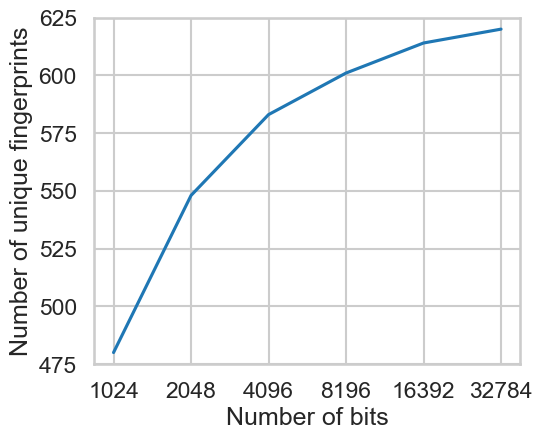

In [6]:
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

fig, ax = plt.subplots(figsize=(5.5,4.5))
ax.plot(unique)
xticks = plt.xticks(range(len(bits)), bits)
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_xlabel('Number of bits')
ax.set_ylabel('Number of unique fingerprints')
ax.set_ylim([475,625])
plt.savefig('scatter_bit-collision.svg',transparent=True)

In [7]:
# calculate fp from SMILES
fps = []
fp_bitvect = []
for smiles in df_features['SMILES']:
	mol = Chem.MolFromSmiles(smiles)
	fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=16392)
	fp_bitvect.append(fp)
	fp_array = np.asarray(fp)
	fps.append(fp_array)

print("Number of compounds converted:", len(fps))
print("Fingerprint length per compound:", len(fps[0]))

Number of compounds converted: 246
Fingerprint length per compound: 16392


## Butina Clustering

### Definitions

In [8]:
def tanimoto_distance_matrix(fp_list):
    """Calculate distance matrix for fingerprint list"""
    dissimilarity_matrix = []
    # Notice how we are deliberately skipping the first and last items in the list
    # because we don't need to compare them against themselves
    for i in range(1, len(fp_list)):
        # Compare the current fingerprint against all the previous ones in the list
        similarities = DataStructs.BulkTanimotoSimilarity(fp_list[i], fp_list[:i])
        # Since we need a distance matrix, calculate 1-x for every element in similarity matrix
        dissimilarity_matrix.extend([1 - x for x in similarities])
    return dissimilarity_matrix

def cluster_fingerprints(fingerprints, cutoff=0.2):
    """Cluster fingerprints
    Parameters:
        fingerprints
        cutoff: threshold for the clustering
    """
    # Calculate Tanimoto distance matrix
    distance_matrix = tanimoto_distance_matrix(fingerprints)
    # Now cluster the data with the implemented Butina algorithm:
    clusters = Butina.ClusterData(distance_matrix, len(fingerprints), cutoff, isDistData=True)
    clusters = sorted(clusters, key=len, reverse=True)
    return clusters

### Choose a reasonable cutoff

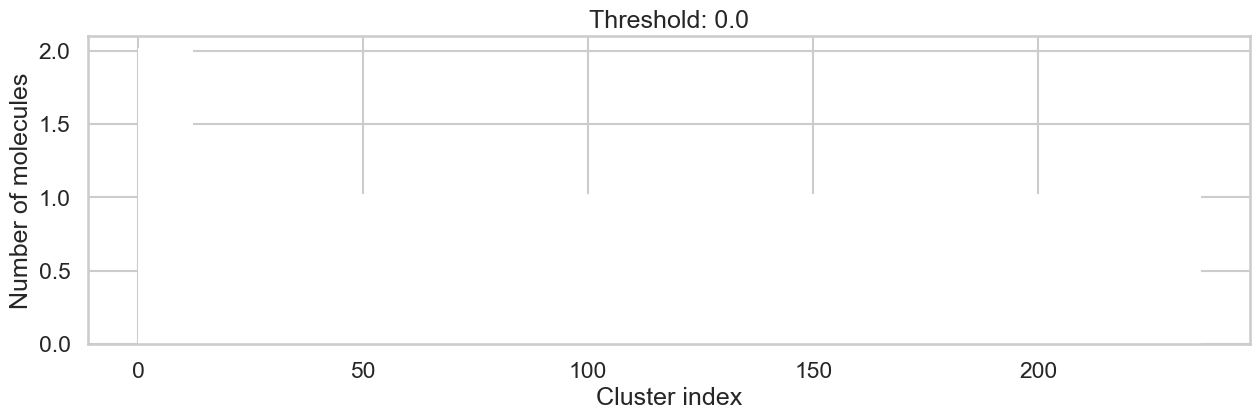

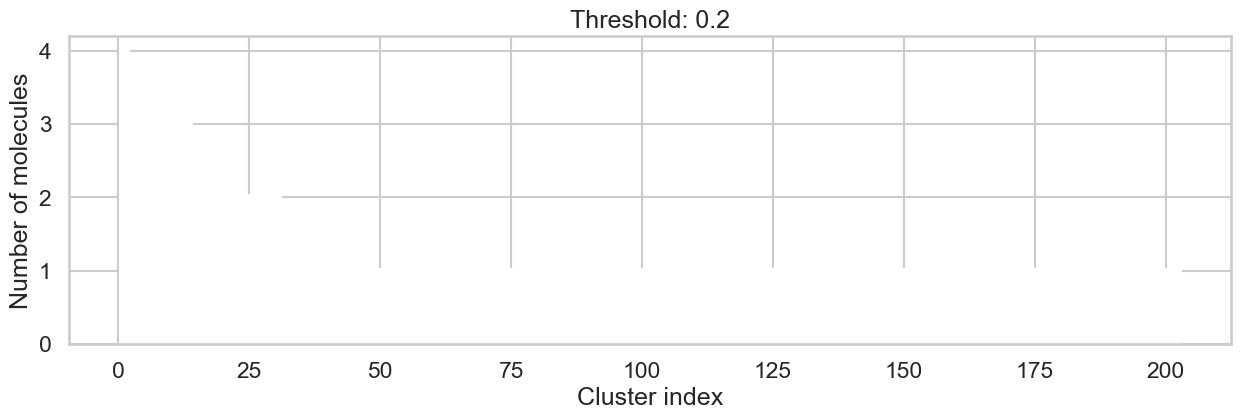

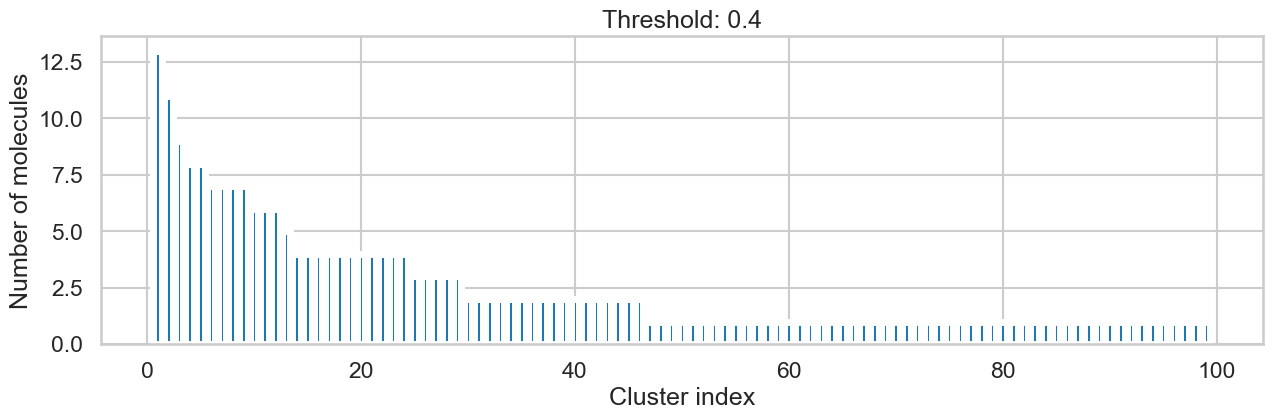

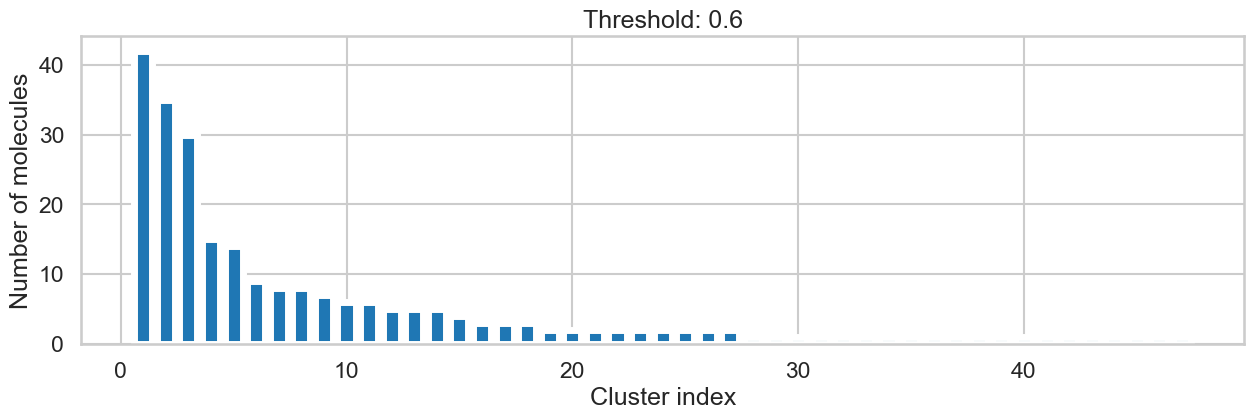

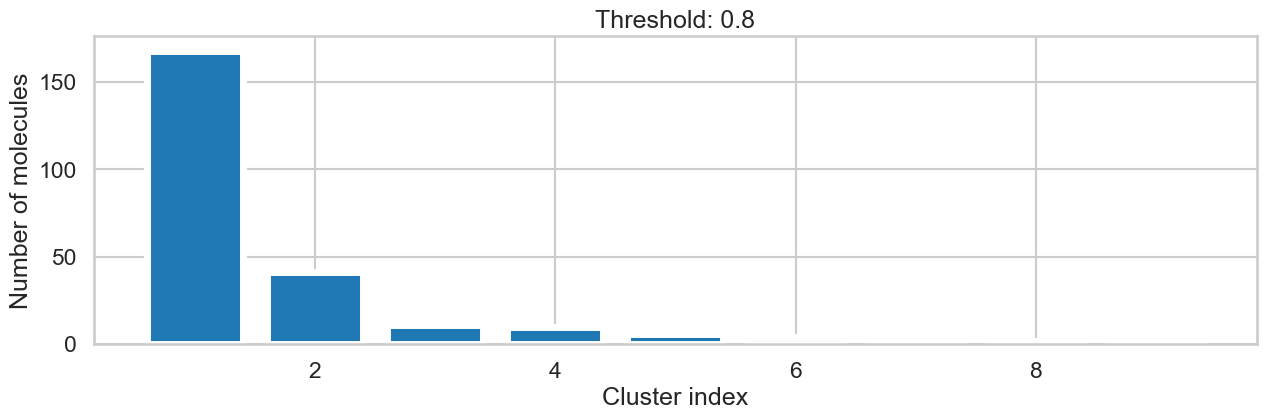

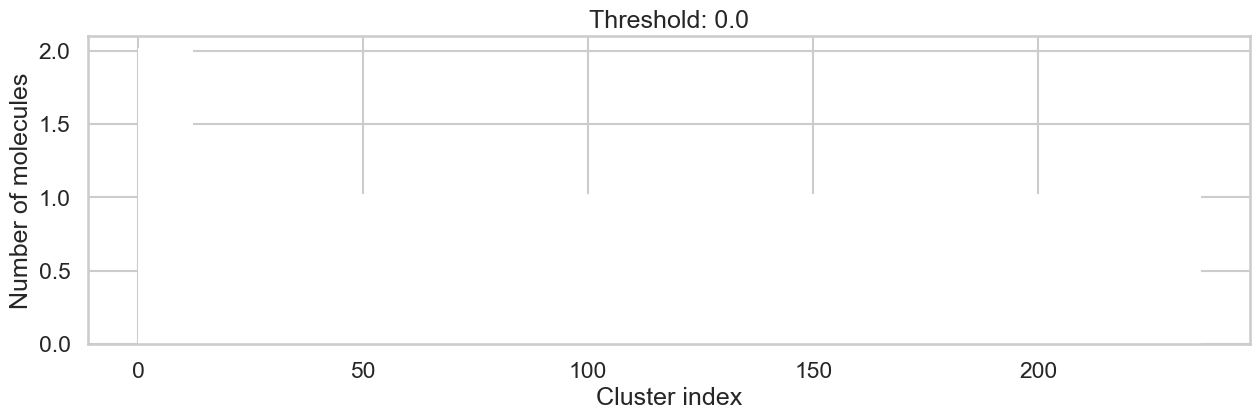

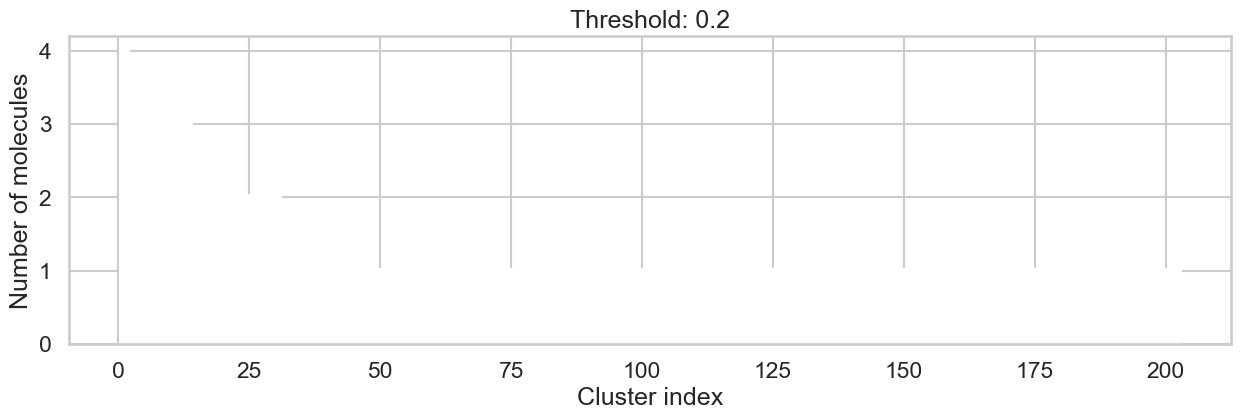

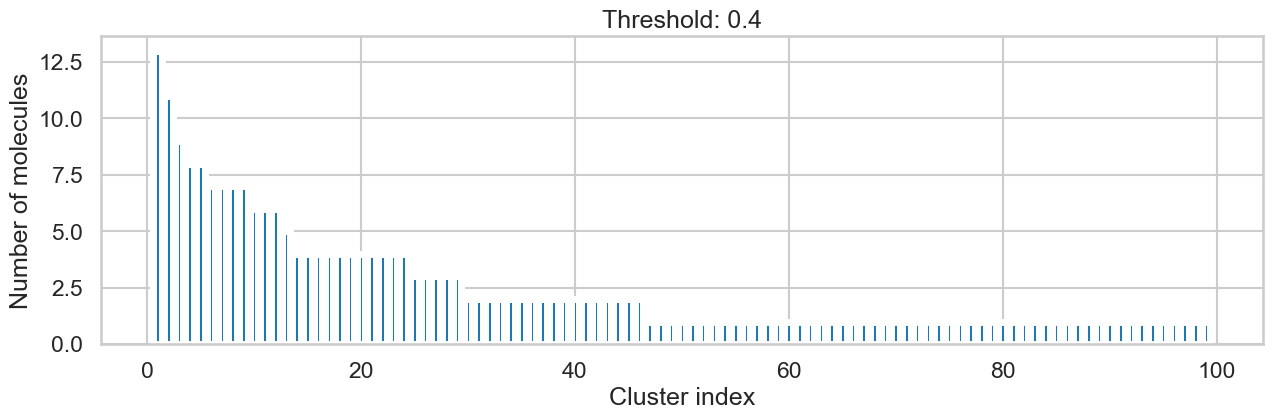

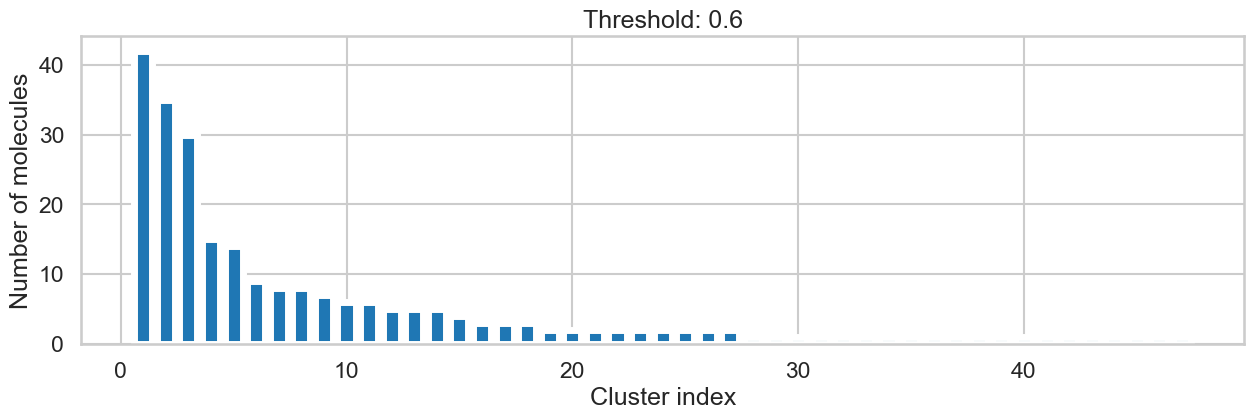

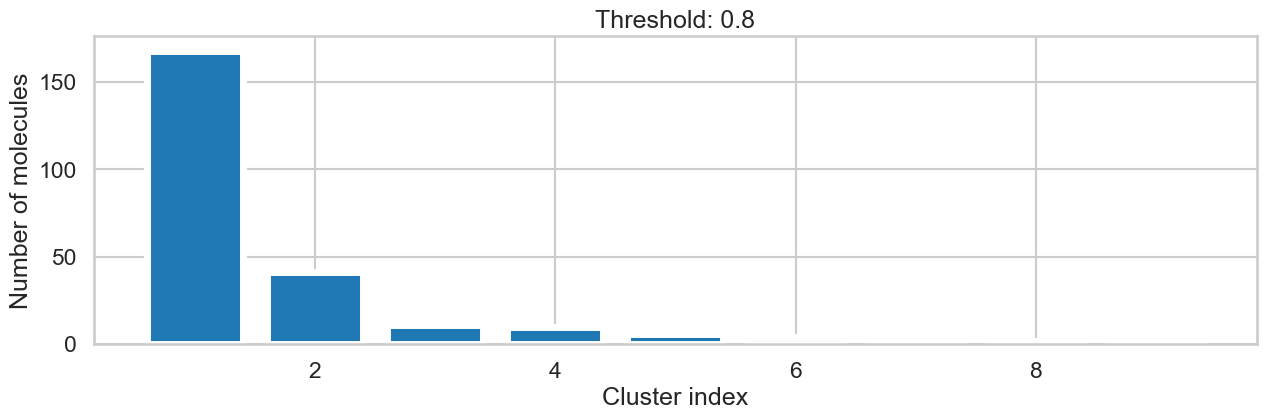

In [9]:
for cutoff in np.arange(0.0, 1.0, 0.2):
    clusters = cluster_fingerprints(fp_bitvect, cutoff=cutoff)
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.set_title(f"Threshold: {cutoff:3.1f}")
    ax.set_xlabel("Cluster index")
    ax.set_ylabel("Number of molecules")
    ax.bar(range(1, len(clusters) + 1), [len(c) for c in clusters], lw=5)
    display(fig)
    fig.savefig(f"Threshold: {cutoff:3.1f}.svg")

the higher the threshold (distance cutoff), the more molecules are considered as similar and, therefore, clustered into less clusters. The lower the threshold, the more small clusters and “singletons” appear.

## Butina targeted for fewer clusters

<BarContainer object of 26 artists>

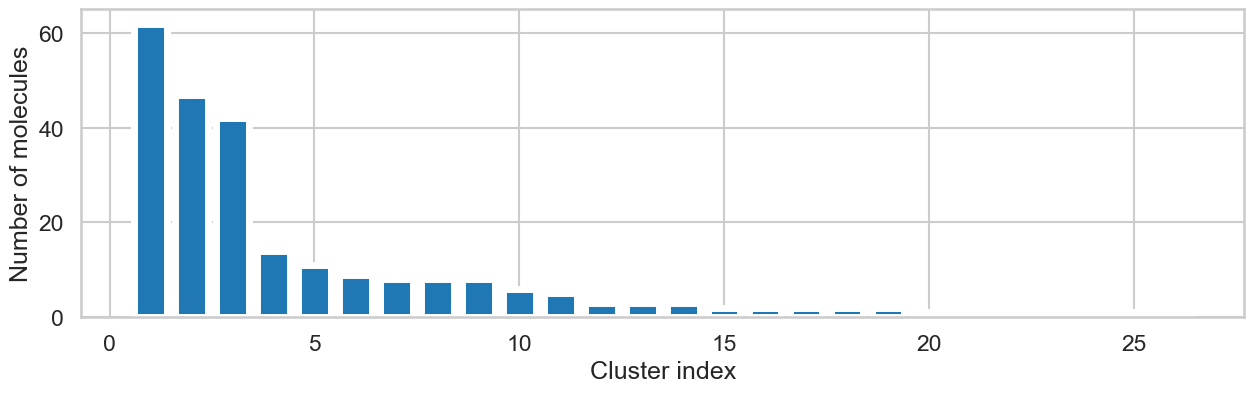

In [10]:
# Set cutoff for a 1/3 of similiarty
clusters = cluster_fingerprints(fp_bitvect, cutoff=0.666)
fig, ax = plt.subplots(figsize=(15, 4))
ax.set_xlabel("Cluster index")
ax.set_ylabel("Number of molecules")
ax.bar(range(1, len(clusters) + 1), [len(c) for c in clusters], lw=5)

In [11]:
# calculate the percentage of molecules attributed to each cluster
perc_cluster = [len(c) / df_features.shape[0] for c in clusters]

# Miscellaneous cluster is made by merging cluster from last independent to the end of the index
for last_cluster in np.arange(8,11):
    print(f"1st cluster %: {round(perc_cluster[0],2)}; last cluster index: {last_cluster+1}; last cluster #: {len(clusters[last_cluster])}; last cluster %: {round(perc_cluster[last_cluster],2)}; Misc. cluster %: {round(1-sum(perc_cluster[0:last_cluster]),2)}")

1st cluster %: 0.25; last cluster index: 9; last cluster #: 8; last cluster %: 0.03; Misc. cluster %: 0.18
1st cluster %: 0.25; last cluster index: 10; last cluster #: 6; last cluster %: 0.02; Misc. cluster %: 0.15
1st cluster %: 0.25; last cluster index: 11; last cluster #: 5; last cluster %: 0.02; Misc. cluster %: 0.13


In [12]:
# cluster selected to be the last
last_cluster = 10 # -1 of the cluster index in the plot

# Create a dictionary to capture the info of each molecules belongs to each cluster
clusters_dict = {}
misc = [] # Miscellaneous
for count, value in enumerate(clusters):
    if count <= last_cluster:
        clusters_dict['cluster'+str(count+1)] = value
    else:
        misc.append(value) # produces a list of lists

# I didn't find a way to append the values of the clusters with few elements to a key of dict called misc. This is a work around that works:
misc = tuple([i for sub in misc for i in sub]) # unpack the list of list into a tuple containg all values
clusters_dict['misc'] = misc # add to the dict

# dict whihc will be used to replace id values by the corresponding cluster
clusters_dict2merge = dict(zip(clusters_dict.values(), clusters_dict.keys())) # exchange cluster1: molecule_index to molecule_index: clusterX

In [13]:
# create a small df for the clustered data
df_clustered = df_features[['ID', 'SMILES']].copy()

# copy index value to a new column
df_clustered['cluster'] = df_clustered.index

# replace index value by the name of the cluster
df_clustered['cluster'] = [next(label for members, label in clusters_dict2merge.items() if idx in members) for idx in df_clustered.index]

# check if df is congruent with the list produced by Butina
print(f"elements per cluster in the list obtained from Butina: {[len(c) for c in clusters]}\n")

print(f"elements per cluster in the df: {[(values,df_clustered['cluster'].value_counts()[values]) for values in sorted(df_clustered['cluster'].unique())]}")

elements per cluster in the list obtained from Butina: [62, 47, 42, 14, 11, 9, 8, 8, 8, 6, 5, 3, 3, 3, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]

elements per cluster in the df: [('cluster1', 62), ('cluster10', 6), ('cluster11', 5), ('cluster2', 47), ('cluster3', 42), ('cluster4', 14), ('cluster5', 11), ('cluster6', 9), ('cluster7', 8), ('cluster8', 8), ('cluster9', 8), ('misc', 26)]


In [14]:
# Convert smiles to mol
df_clustered['mol'] = df_clustered['SMILES'].apply(lambda x: Chem.MolFromSmiles(x))

In [15]:
# collect the index of the centroid of each cluster
idx_centroid = []
for keys in clusters_dict:
    idx_centroid.append(clusters_dict[keys][0])
    print(keys,clusters_dict[keys][0])

cluster1 31
cluster2 165
cluster3 223
cluster4 203
cluster5 17
cluster6 5
cluster7 3
cluster8 115
cluster9 104
cluster10 236
cluster11 238
misc 26


In [16]:
# remove the Miscellaneous centroid
cluster_centroid = idx_centroid[:-1]

In [17]:
df_clustered[['ID','cluster']].to_csv("clusters_cutoff_0_66.csv", index=False)

#### Draw centroids

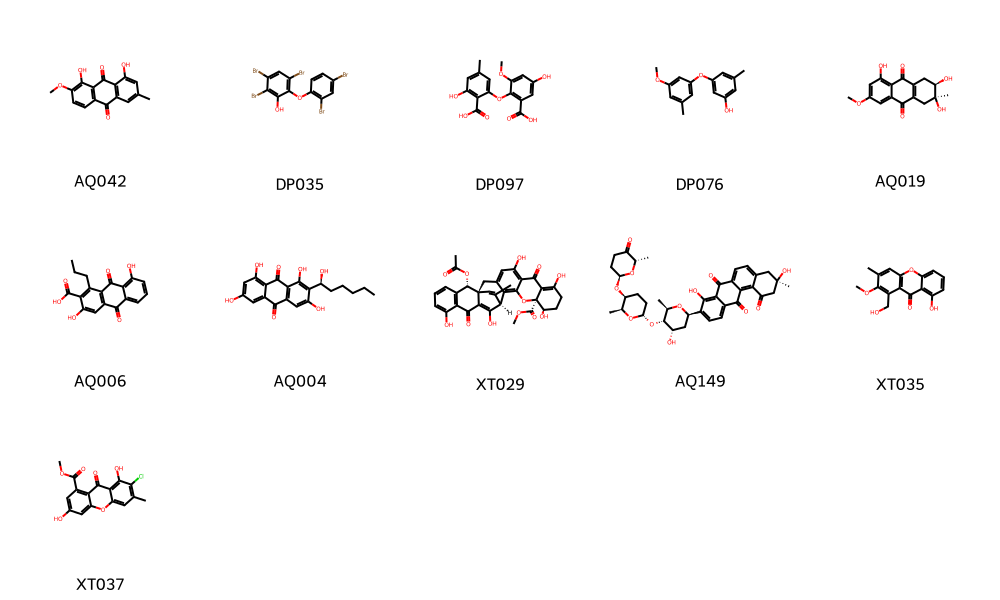

In [18]:
# Draw clusters centroids
Draw.MolsToGridImage(df_clustered.iloc[cluster_centroid,3],molsPerRow=5, useSVG=True, legends=list(df_clustered.iloc[cluster_centroid,0]))

# Save grid
#grid = Draw.MolsToGridImage(df_clustered.iloc[cluster_centroid,3],molsPerRow=5, useSVG=True, legends=list(df_clustered.iloc[cluster_centroid,0]))
#with open('grid.svg', 'w') as f:
#    f.write(grid.data)

#### Draw similarity maps

In [19]:
# collect the index of the most dissimilar compound in each cluster
idx_dissimilar = []
for keys in clusters_dict:
    idx_dissimilar.append(clusters_dict[keys][-1])
    print(keys,clusters_dict[keys][-1])

cluster1 212
cluster2 217
cluster3 228
cluster4 213
cluster5 84
cluster6 108
cluster7 88
cluster8 235
cluster9 106
cluster10 243
cluster11 239
misc 245


In [20]:
# remove the Miscellaneous dissimilar compound
cluster_dissimilar = idx_dissimilar[:-1]

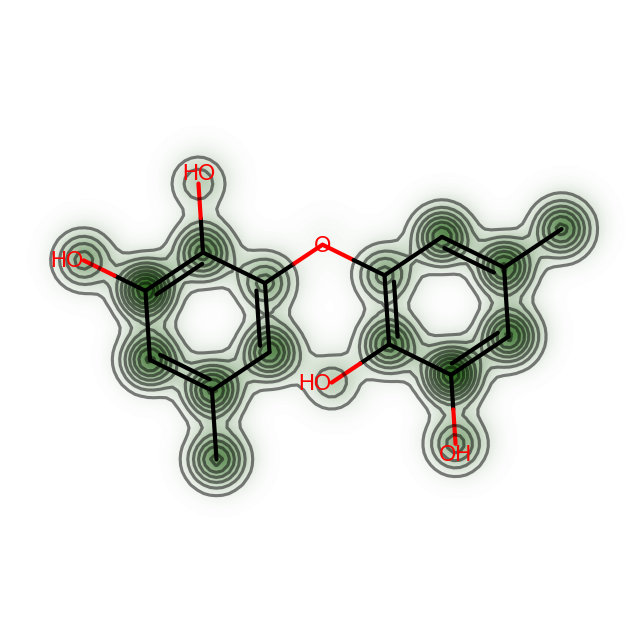

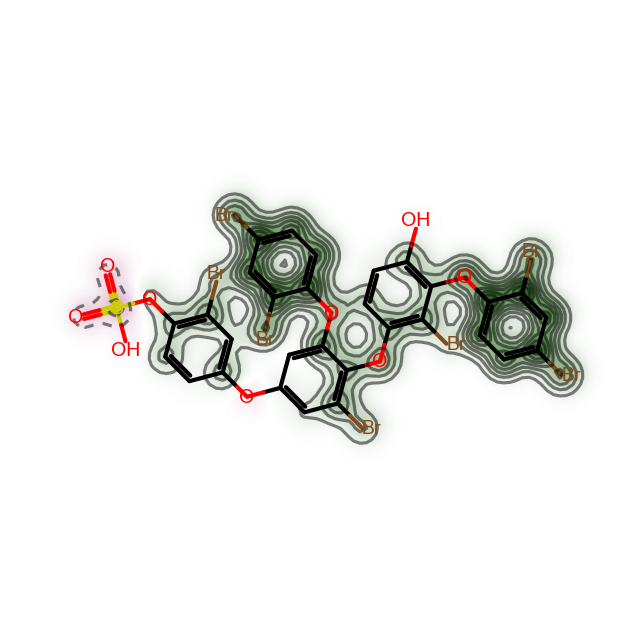

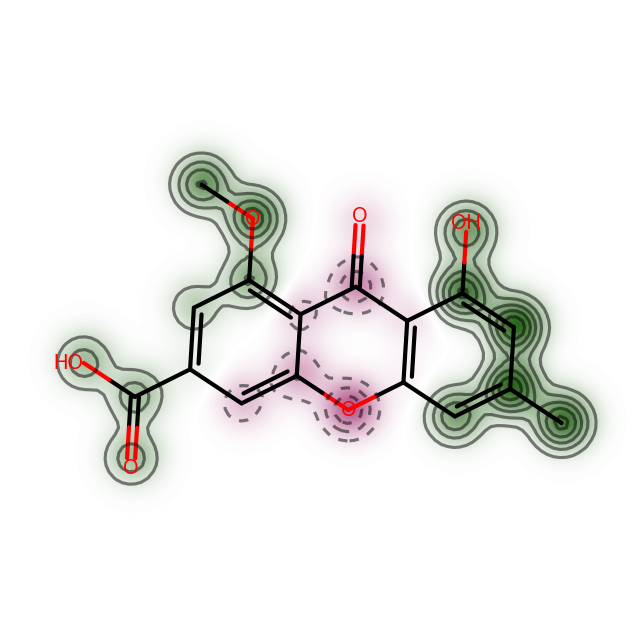

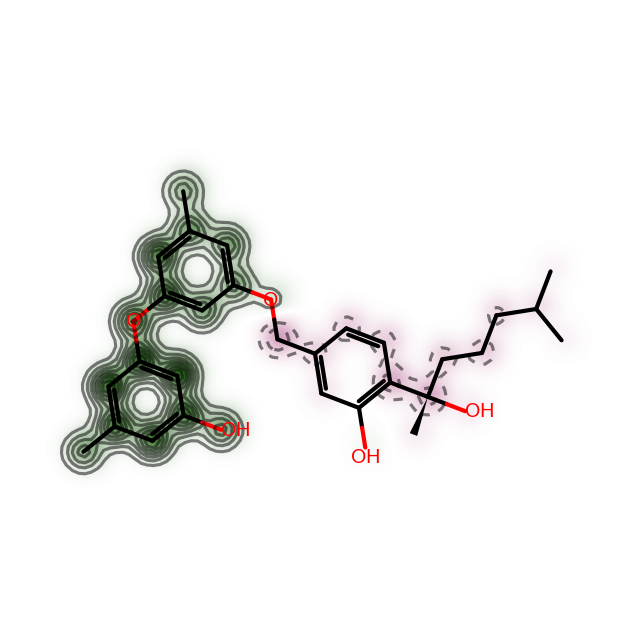

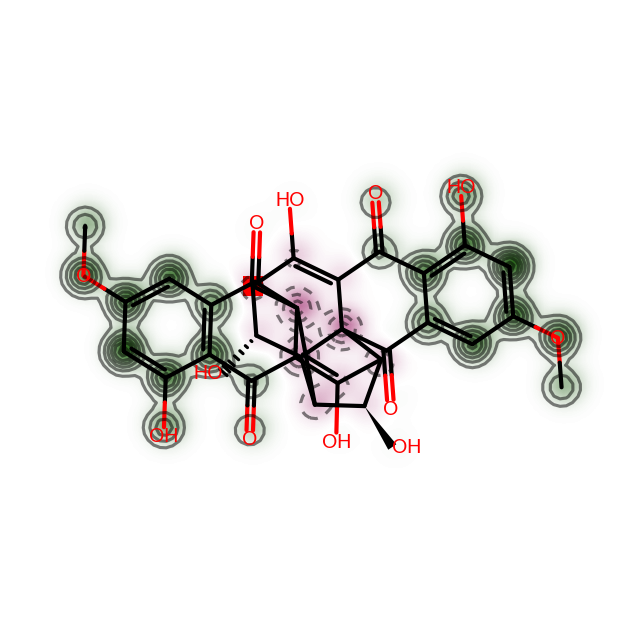

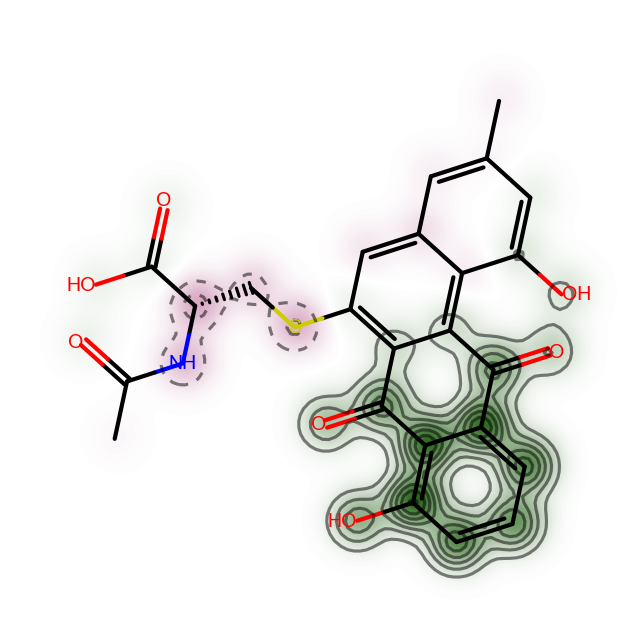

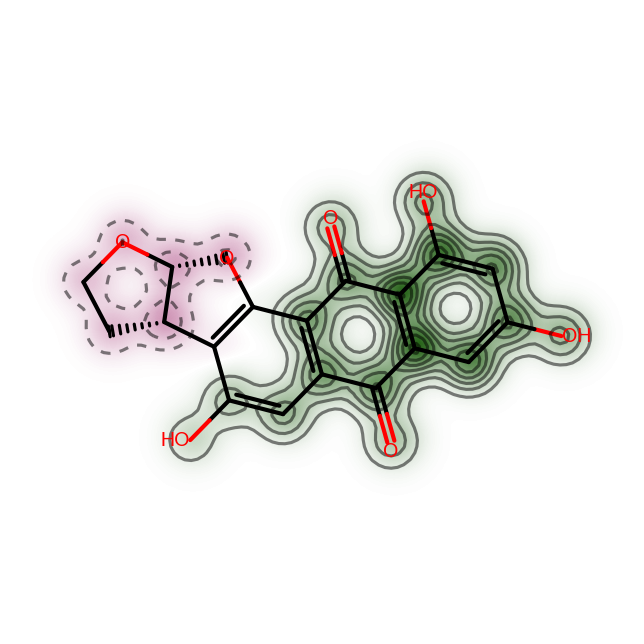

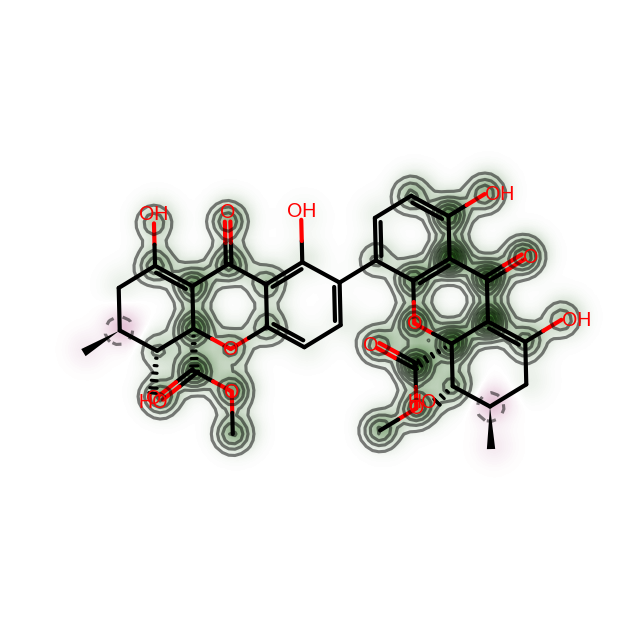

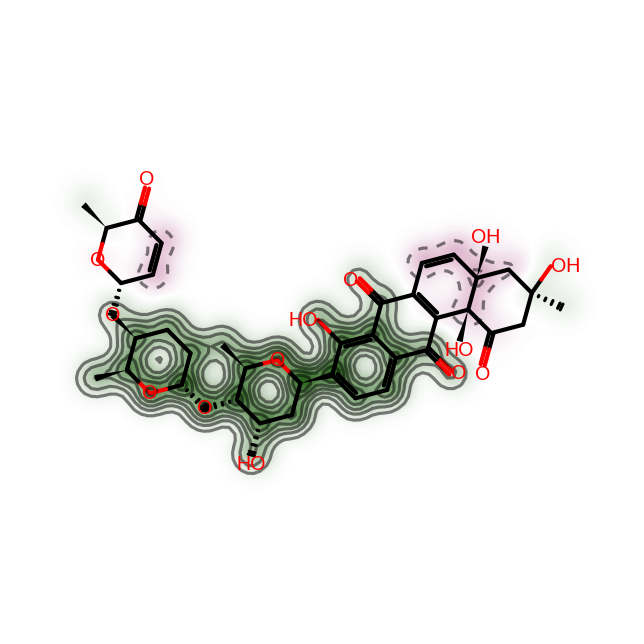

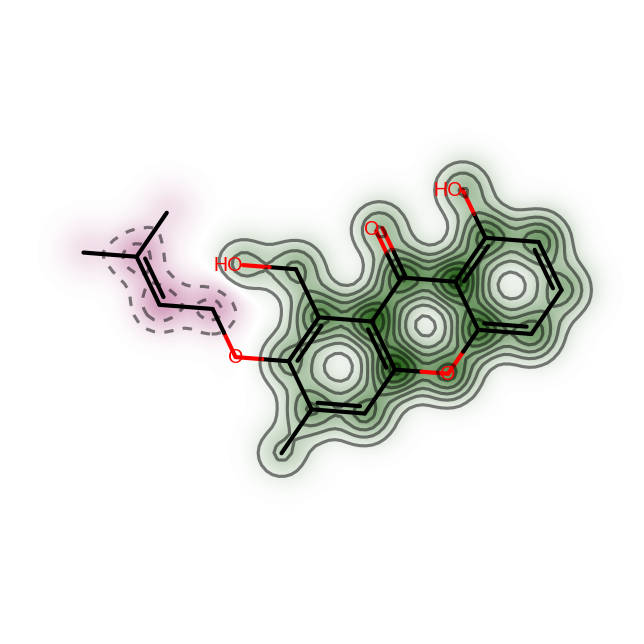

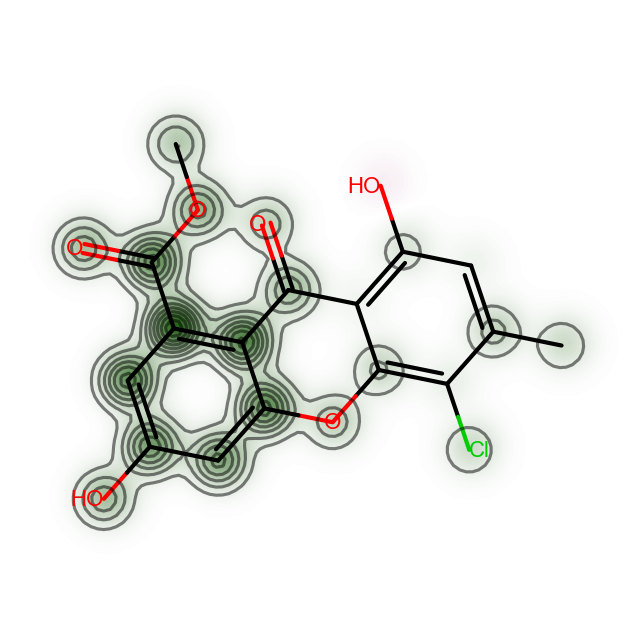

In [21]:
# Draw similarity maps between the centroid and the most dissimilar compound within each cluster

for i in range(len(cluster_centroid)):
    refmol = df_clustered.iloc[cluster_centroid[i],3]
    mol = df_clustered.iloc[cluster_dissimilar[i],3]
    fig, maxweight = SimilarityMaps.GetSimilarityMapForFingerprint(refmol,mol, lambda m, i: SimilarityMaps.GetMorganFingerprint(m, i, radius=2, nBits=4096, fpType='bv'))
    #fig.savefig('cluster'+str(i)+'.svg',bbox_inches='tight')

## Butina targeted for homogenity

### Clusters analysis

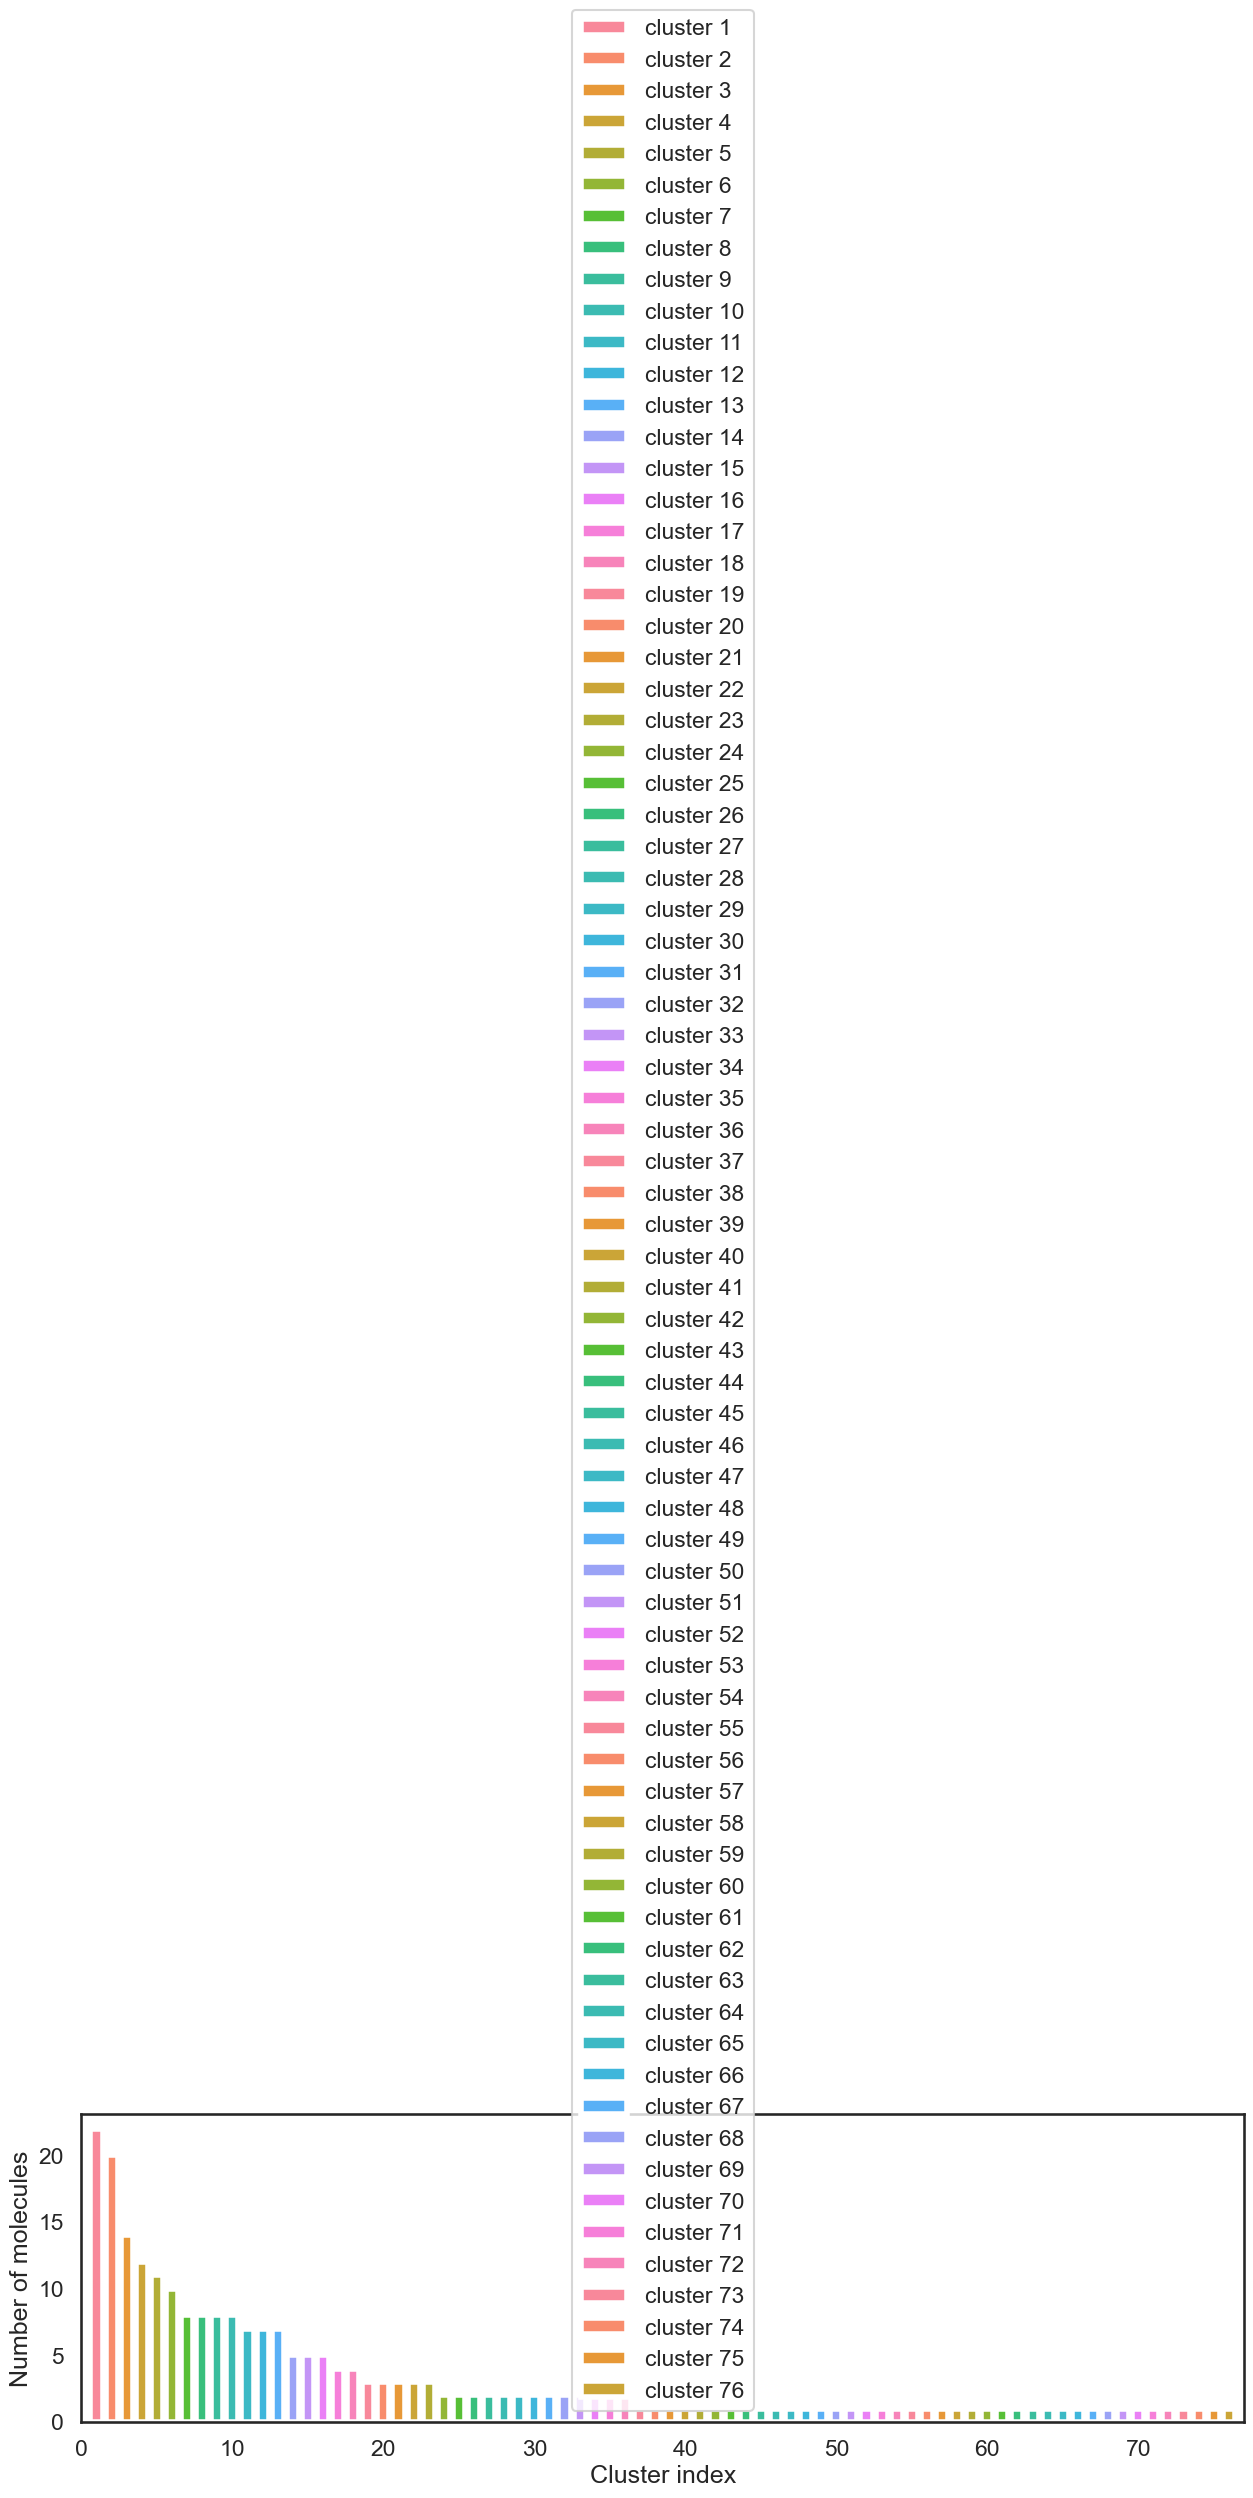

In [22]:
# Set cutoff for a half of similiarty
clusters = cluster_fingerprints(fp_bitvect, cutoff=0.5)

# plot 
sns.set_context("talk")
sns.set_style("white")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
colors = sns.husl_palette(n_colors= 18, l=0.7)

label= ['cluster '+str(x) for x in range(1, len(clusters) + 1)]

fig, ax = plt.subplots(figsize=(15, 4))
a = ax.bar(range(1, len(clusters) + 1), [len(c) for c in clusters], lw=4, color=colors)

ax.set_xlabel("Cluster index")
ax.set_ylabel("Number of molecules")

ax.set_xlim([0,len(clusters)+1])

ax.legend(handles=a,labels=label)


plt.savefig('plots/bar_clusters.svg',transparent=True)

In [23]:
print(len(clusters))

76


In [24]:
# select the range of idx to check the difference
idx_range_cluster = [14,20]

# calculate the percentage of molecules attributed to each cluster
perc_cluster = [len(c) / df_features.shape[0] for c in clusters]

# Miscellaneous cluster is made by merging cluster from last independent to the end of the index
for last_cluster in np.arange(idx_range_cluster[0],idx_range_cluster[1]):
    print(
        f"1st cluster %: {round(perc_cluster[0],2)}; last cluster index: {last_cluster+1}; last cluster #: {len(clusters[last_cluster])}; last cluster %: {round(perc_cluster[last_cluster],2)}; Misc. cluster %: {round(1-sum(perc_cluster[0:last_cluster]),2)}"
        )

1st cluster %: 0.09; last cluster index: 15; last cluster #: 5; last cluster %: 0.02; Misc. cluster %: 0.4
1st cluster %: 0.09; last cluster index: 16; last cluster #: 5; last cluster %: 0.02; Misc. cluster %: 0.38
1st cluster %: 0.09; last cluster index: 17; last cluster #: 4; last cluster %: 0.02; Misc. cluster %: 0.36
1st cluster %: 0.09; last cluster index: 18; last cluster #: 4; last cluster %: 0.02; Misc. cluster %: 0.35
1st cluster %: 0.09; last cluster index: 19; last cluster #: 3; last cluster %: 0.01; Misc. cluster %: 0.33
1st cluster %: 0.09; last cluster index: 20; last cluster #: 3; last cluster %: 0.01; Misc. cluster %: 0.32


In [25]:
# cluster selected to be the last
last_cluster = 18 # -1 of the cluster index in the plot

# Create a dictionary to capture the info of each molecules belongs to each cluster
clusters_dict = {}
misc = [] # Miscellaneous
for count, value in enumerate(clusters):
    if count <= last_cluster:
        clusters_dict['cluster'+str(count+1)] = value
    else:
        misc.append(value) # produces a list of lists

# I didn't find a way to append the values of the clusters with few elements to a key of dict called misc. This is a work around that works:
misc = tuple([i for sub in misc for i in sub]) # unpack the list of list into a tuple containg all values
clusters_dict['misc'] = misc # add to the dict

# dict whihc will be used to replace id values by the corresponding cluster
clusters_dict2merge = dict(zip(clusters_dict.values(), clusters_dict.keys())) # exchange cluster1: molecule_index to molecule_index: clusterX

In [26]:
# create a small df for the clustered data
df_clustered = df_features[['ID','SMILES']].copy()

# copy index value to a new column
df_clustered['cluster'] = df_clustered.index

# replace index value by the name of the cluster
df_clustered['cluster'] = [next(label for members, label in clusters_dict2merge.items() if idx in members) for idx in df_clustered.index]

# check if df is congruent with the list produced by Butina
print(f"elements per cluster in the list obtained from Butina: {[len(c) for c in clusters]}\n")

print(f"elements per cluster in the df: {[(values,df_clustered['cluster'].value_counts()[values]) for values in sorted(df_clustered['cluster'].unique())]}")

elements per cluster in the list obtained from Butina: [22, 20, 14, 12, 11, 10, 8, 8, 8, 8, 7, 7, 7, 5, 5, 5, 4, 4, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

elements per cluster in the df: [('cluster1', 22), ('cluster10', 8), ('cluster11', 7), ('cluster12', 7), ('cluster13', 7), ('cluster14', 5), ('cluster15', 5), ('cluster16', 5), ('cluster17', 4), ('cluster18', 4), ('cluster19', 3), ('cluster2', 20), ('cluster3', 14), ('cluster4', 12), ('cluster5', 11), ('cluster6', 10), ('cluster7', 8), ('cluster8', 8), ('cluster9', 8), ('misc', 78)]


In [27]:
# Convert smiles to mol
df_clustered['mol'] = df_clustered['SMILES'].apply(lambda x: Chem.MolFromSmiles(x))

In [28]:
# collect the index of the centroid and of the most dissimilar compound in each cluster
idx_centroid = []
idx_dissimilar = []
for keys in clusters_dict:
    idx_centroid.append(clusters_dict[keys][0])
    idx_dissimilar.append(clusters_dict[keys][-1])
    print(keys,df_clustered.iloc[clusters_dict[keys][0],0],df_clustered.iloc[clusters_dict[keys][-1],0],sep='\t')

cluster1	DP016	DP068
cluster2	AQ022	AQ155
cluster3	DP096	DP101
cluster4	DP004	DP079
cluster5	AQ107	AQ113
cluster6	DP038	DP087
cluster7	AQ125	AQ154
cluster8	DP012	DP074
cluster9	AQ145	AQ147
cluster10	AQ027	AQ131
cluster11	DP053	DP052
cluster12	XT033	XT032
cluster13	AQ071	AQ023
cluster14	BZ004	BZ016
cluster15	DP083	DP082
cluster16	AQ099	AQ098
cluster17	AQ149	AQ151
cluster18	AQ018	AQ017
cluster19	DP077	DP085
misc	DP090	AQ030


In [29]:
# remove the Miscellaneous centroid
cluster_centroid = idx_centroid[:-1]

In [30]:
df_clustered[['ID','cluster']].to_csv("clusters_cutoff_0_5.csv", index=False)

### Draw centroids

In [31]:
# Draw clusters centroids
Draw.MolsToGridImage(df_clustered.iloc[cluster_centroid,3],molsPerRow=5, useSVG=True, legends=list(df_clustered.iloc[cluster_centroid,0]))

# Save grid
grid = Draw.MolsToGridImage(df_clustered.iloc[cluster_centroid,3],molsPerRow=5, useSVG=True, legends=list(df_clustered.iloc[cluster_centroid,0]))
with open('chem_centroids-grid.svg', 'w') as f:
    f.write(grid.data)

### Draw similarity maps

In [32]:
# collect the index of the most dissimilar compound in each cluster
idx_dissimilar = []
for keys in clusters_dict:
    idx_dissimilar.append(clusters_dict[keys][-1])
    print(keys,df_clustered.iloc[clusters_dict[keys][-1],0])

cluster1 DP068
cluster2 AQ155
cluster3 DP101
cluster4 DP079
cluster5 AQ113
cluster6 DP087
cluster7 AQ154
cluster8 DP074
cluster9 AQ147
cluster10 AQ131
cluster11 DP052
cluster12 XT032
cluster13 AQ023
cluster14 BZ016
cluster15 DP082
cluster16 AQ098
cluster17 AQ151
cluster18 AQ017
cluster19 DP085
misc AQ030


In [33]:
# remove the Miscellaneous dissimilar compound
cluster_dissimilar = idx_dissimilar[:-1]

In [34]:
# Draw most dissimilar molecule centroids
grid = Draw.MolsToGridImage(df_clustered.iloc[cluster_dissimilar,3],molsPerRow=5, useSVG=True, legends=list(df_clustered.iloc[cluster_dissimilar,0]))
with open('chem_dissimilar-grid.svg', 'w') as f:
    f.write(grid.data)

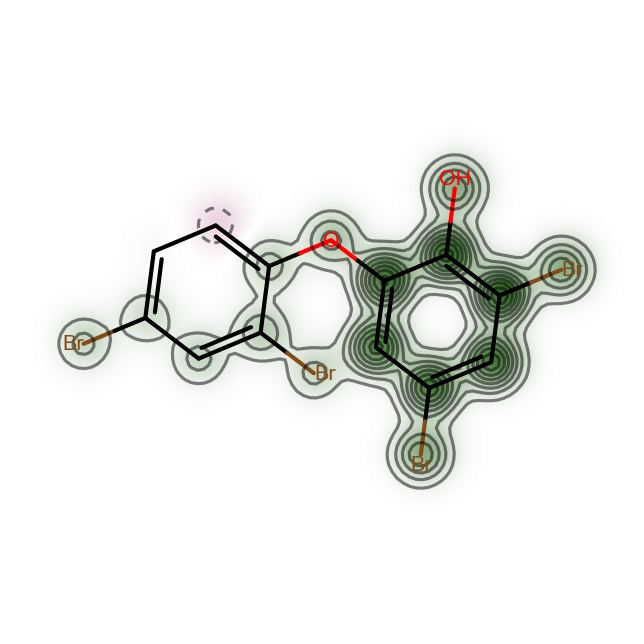

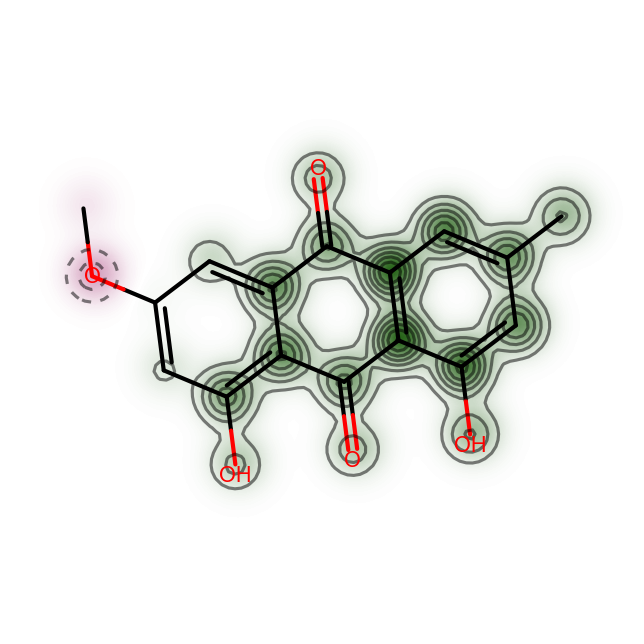

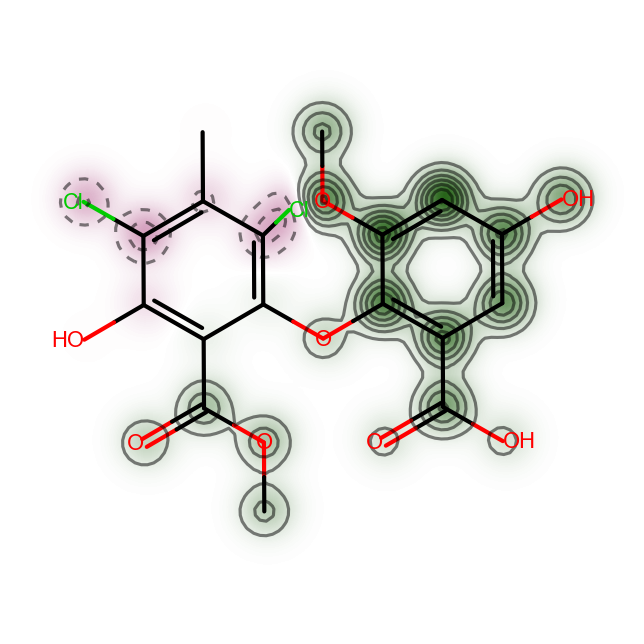

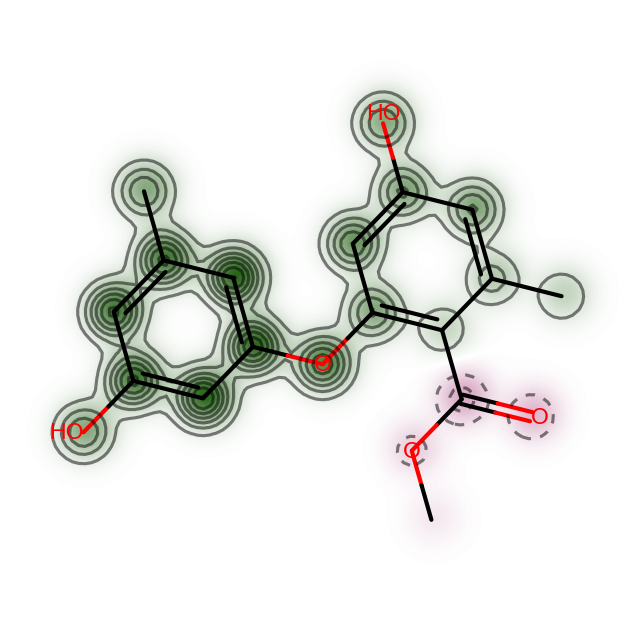

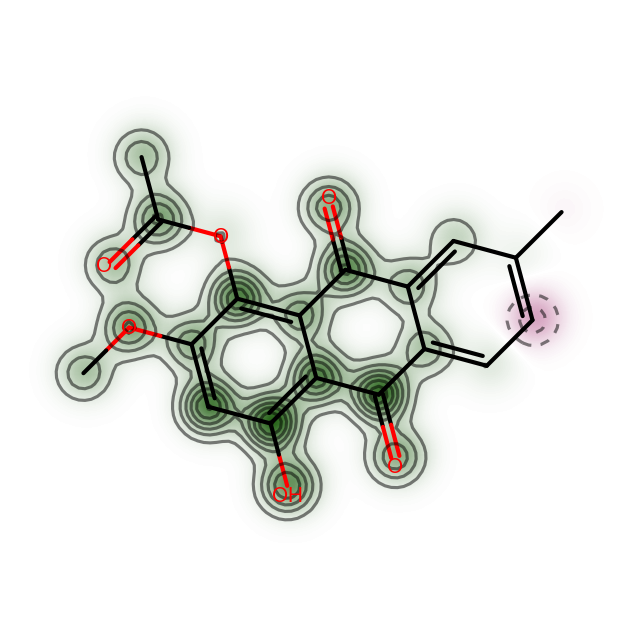

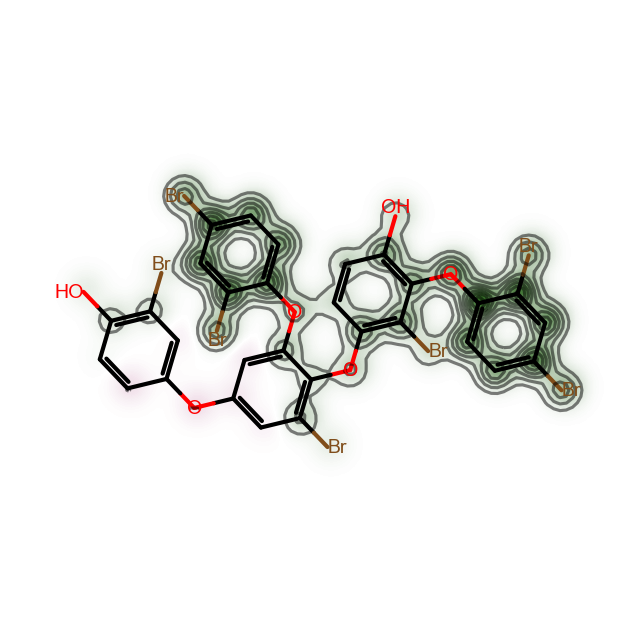

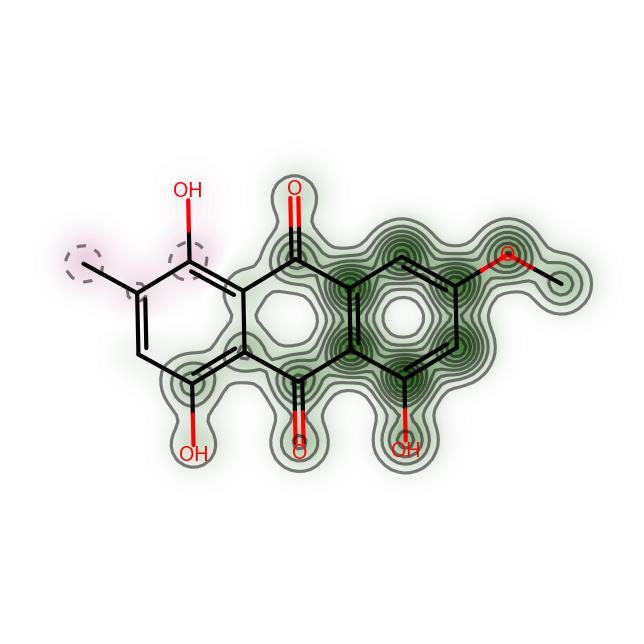

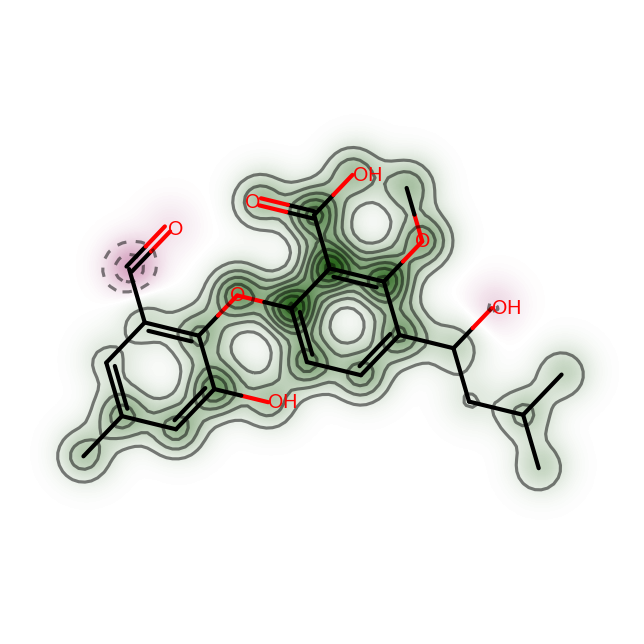

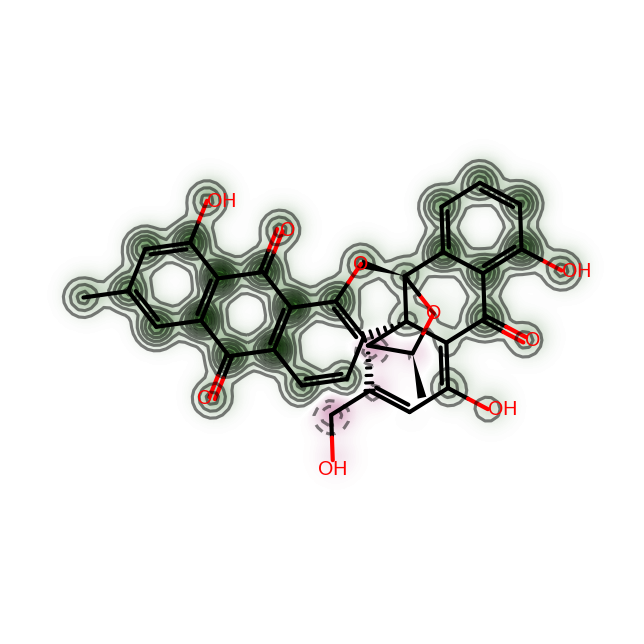

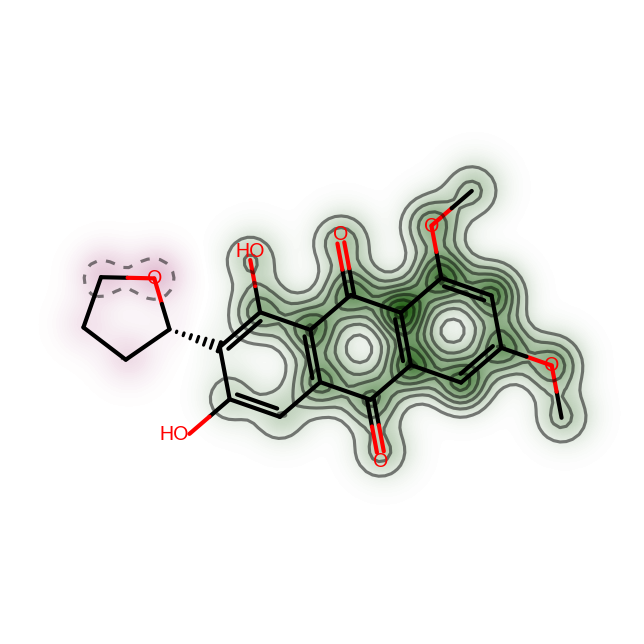

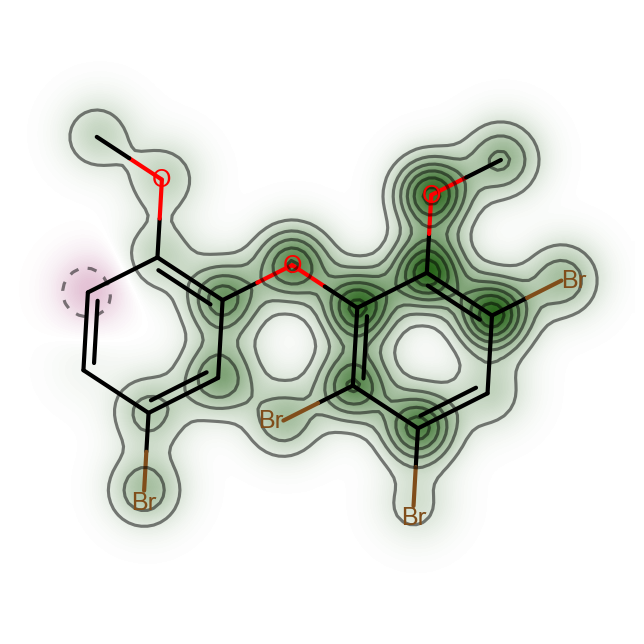

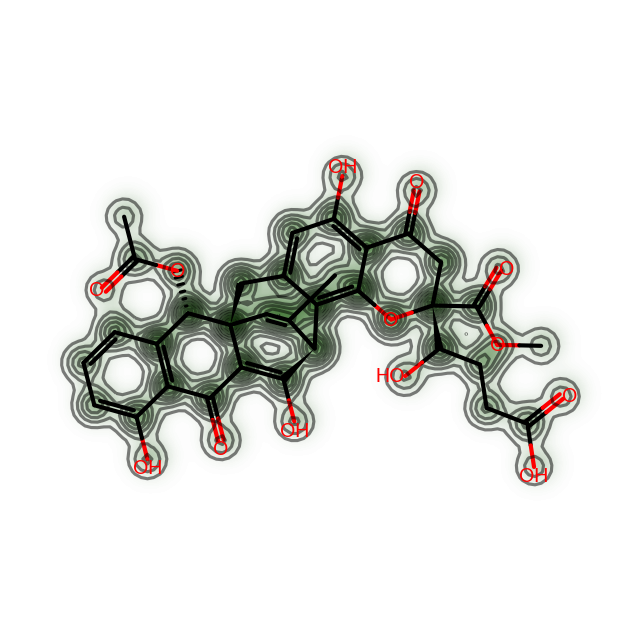

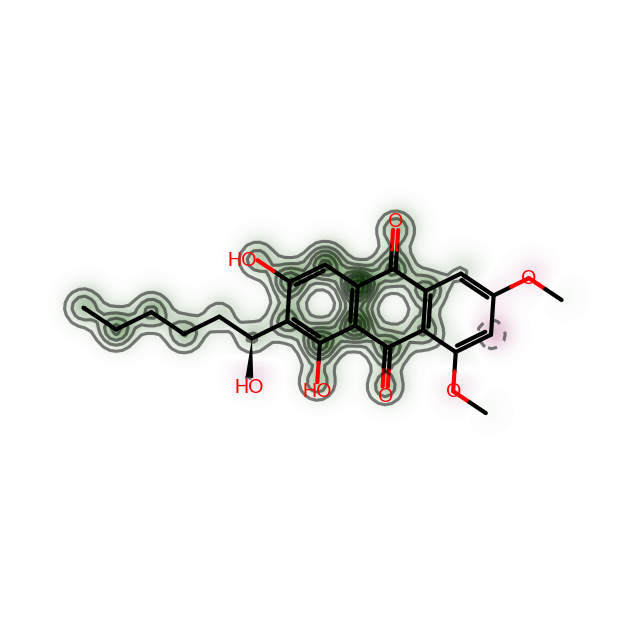

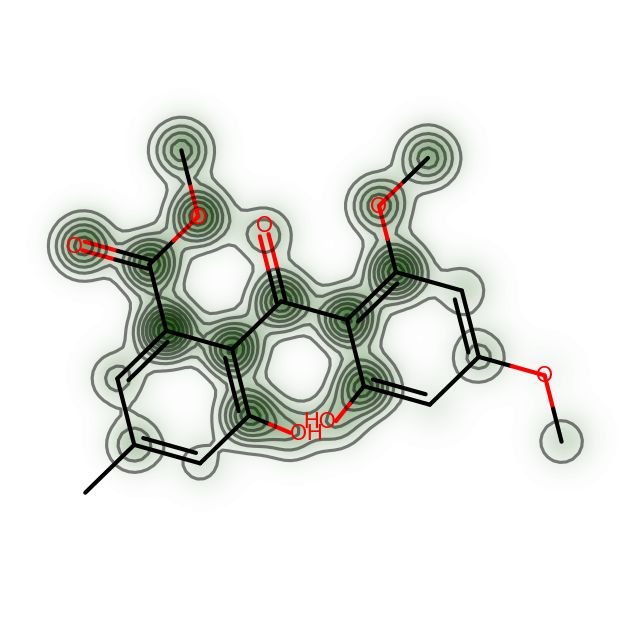

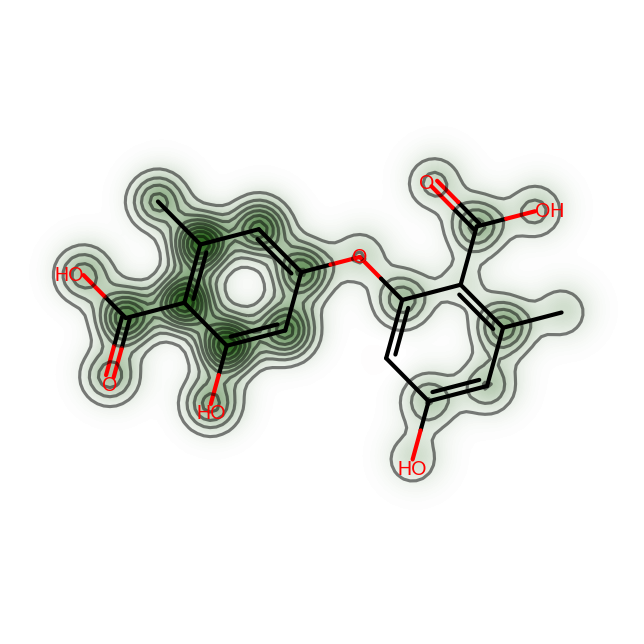

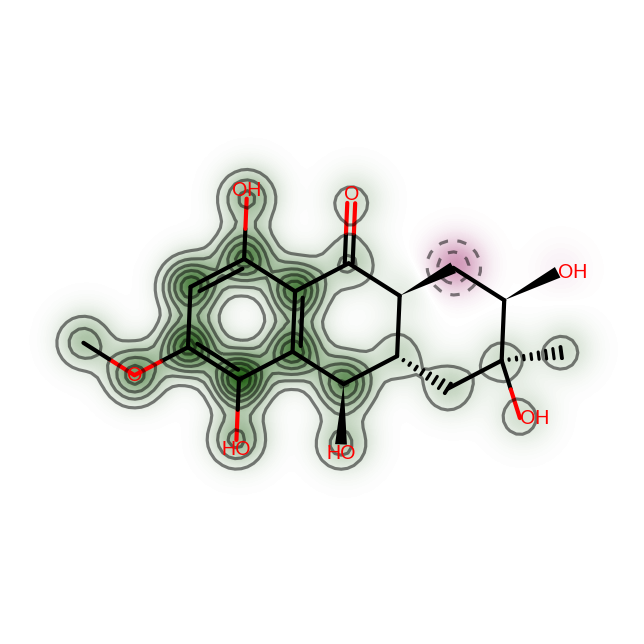

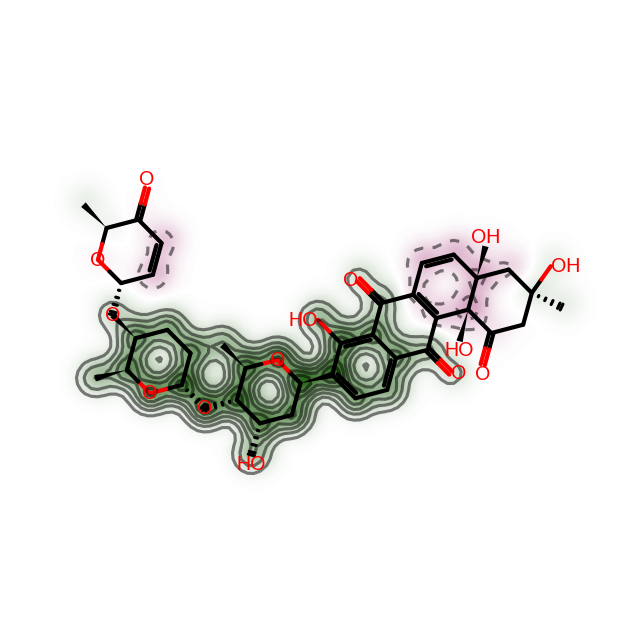

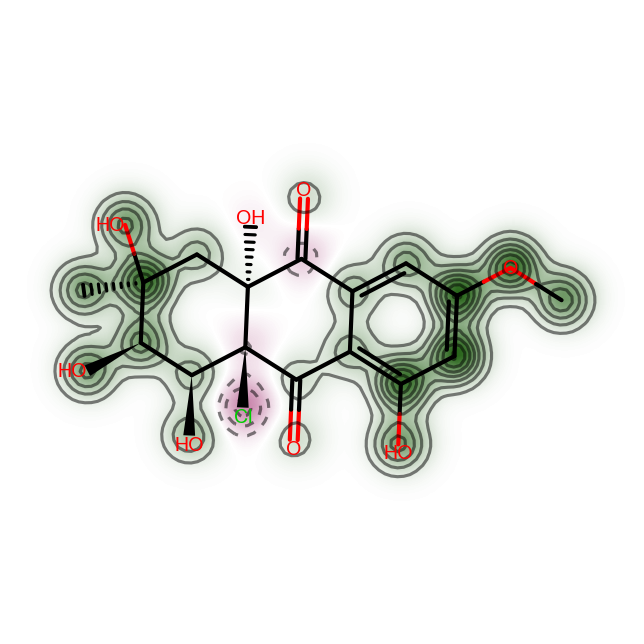

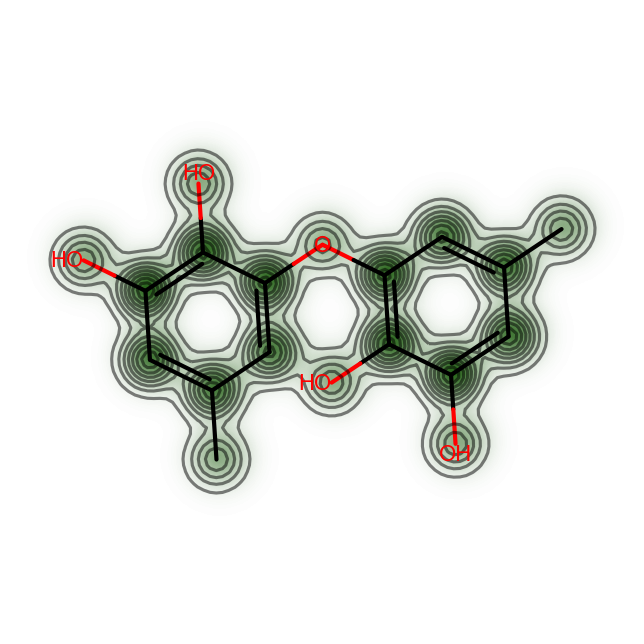

In [35]:
# Draw similarity maps between the centroid and the most dissimilar compound within each cluster

for i in range(len(cluster_centroid)):
    refmol = df_clustered.iloc[cluster_centroid[i],3]
    mol = df_clustered.iloc[cluster_dissimilar[i],3]
    fig, maxweight = SimilarityMaps.GetSimilarityMapForFingerprint(refmol,mol, lambda m, i: SimilarityMaps.GetMorganFingerprint(m, i, radius=2, nBits=16392, fpType='bv'))
    fig.savefig('chem_'+df_clustered.iloc[cluster_dissimilar[i],0]+'-cluster'+str(i+1)+'.svg',bbox_inches='tight')